# TP4 - Escalado de Datos
Materia: Diseño de Bases de Datos II  
Carrera: Ingeniería en Informática - Universidad de Mendoza  
Alumno: Francisco Rodeles  

## Consigna

Se quiere utilizar el conjunto de datos guardado en el archivo AirQualityUCI.csv para realizar un análisis de regresión. El algoritmo que se quiere utilizar requiere que los valores numéricos se encuentren en un rango entre 0 y 1. 

- Seleccionar un método de escalado y aplicarlo
- Justificar la elección

## 1. Importación de Librerías y Carga del Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    MaxAbsScaler,
    RobustScaler,
    QuantileTransformer
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Carga del archivo AirQualityUCI.csv
df = pd.read_csv('../data/AirQualityUCI.csv')
print(f"Dimensiones iniciales del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones iniciales del dataset: 9357 filas x 20 columnas


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,10/03/2004,18.00.00,2,6,1360,150,11,9,1046,166,1056,113,1692,1268,13,6,48.0,9.0,0.0,7578.0
1,10/03/2004,19.00.00,2,1292,112,9,4,955,103,1174,92,1559,972,13,3,47,7.0,0.0,7255.0,NaN
2,10/03/2004,20.00.00,2,2,1402,88,9,0,939,131,1140,114,1555,1074,11,9,54.0,0.0,0.0,7502.0
3,10/03/2004,21.00.00,2,2,1376,80,9,2,948,172,1092,122,1584,1203,11,0,60.0,0.0,0.0,7867.0
4,10/03/2004,22.00.00,1,6,1272,51,6,5,836,131,1205,116,1490,1110,11,2,59.0,6.0,0.0,7888.0


## 2. Exploración y Selección de Columnas Numéricas

Al inspeccionar la estructura del archivo se observa que:
- Las primeras dos columnas (Date y Time) corresponden a la fecha y hora de la medición.
- Existen 13 atributos numéricos correspondientes a las mediciones de gases contaminantes, sensores químicos y variables meteorológicas: CO(GT), PT08.S1(CO), NMHC(GT), C6H6(GT), PT08.S2(NMHC), NOx(GT), PT08.S3(NOx), NO2(GT), PT08.S4(NO2), PT08.S5(O3), T, RH y AH.
- Al final del archivo aparecen 5 columnas sin nombre (Unnamed: 15 a Unnamed: 19) producto de comas adicionales en la exportación del CSV original, las cuales contienen valores desplazados y datos nulos, por lo que se descartan para trabajar sobre las 13 variables reales del dominio.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   int64  
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   int64  
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   int64  
 13  RH             9357 non-null   int64  
 14  AH             9357 non-null   int64  
 15  Unnamed: 15    9357 non-null   int64  
 16  Unnamed: 16    9296 non-null   float64
 17  Unnamed: 17    8991 non-null   float64
 18  Unnamed: 18    8991

In [3]:
# Selección de las 13 columnas numéricas de interés
columns_names = [
    'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)',
    'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
    'T', 'RH', 'AH'
]

df_cols = df[columns_names].copy(deep=True)
display(df_cols.describe().T)

,count,mean,std,min,25%,50%,75%,max
CO(GT),9357.0,-34.578177,77.484093,-200.0,0.0,1.0,2.0,11.0
PT08.S1(CO),9357.0,240.766912,455.944990,-200.0,3.0,6.0,9.0,2040.0
NMHC(GT),9357.0,771.191621,598.477832,-200.0,39.0,981.0,1171.0,2008.0
C6H6(GT),9357.0,-117.529016,147.670771,-200.0,-200.0,-200.0,4.0,1189.0
PT08.S2(NMHC),9357.0,1.601047,37.649516,-200.0,3.0,6.0,11.0,63.0
NOx(GT),9357.0,210.169285,408.532426,-200.0,2.0,6.0,9.0,1889.0
PT08.S3(NOx),9357.0,678.366784,507.793366,-200.0,383.0,791.0,1040.0,2214.0
NO2(GT),9357.0,365.927007,351.573404,-200.0,110.0,247.0,600.0,2331.0
PT08.S4(NO2),9357.0,589.606284,469.129574,-200.0,145.0,695.0,891.0,2683.0
PT08.S5(O3),9357.0,416.914396,623.408030,-200.0,84.0,124.0,212.0,2684.0


## 3. Análisis Visual de los Datos Originales (Rangos y Valores Atípicos)

Antes de elegir el escalador se grafican los atributos originales para observar la diferencia de escalas entre columnas y la presencia de valores atípicos. En este dataset de calidad del aire, el valor -200 fue utilizado originalmente como código centinela para indicar mediciones faltantes del sensor, lo que genera valores atípicos negativos muy marcados además de los picos altos propios de la contaminación ambiental.

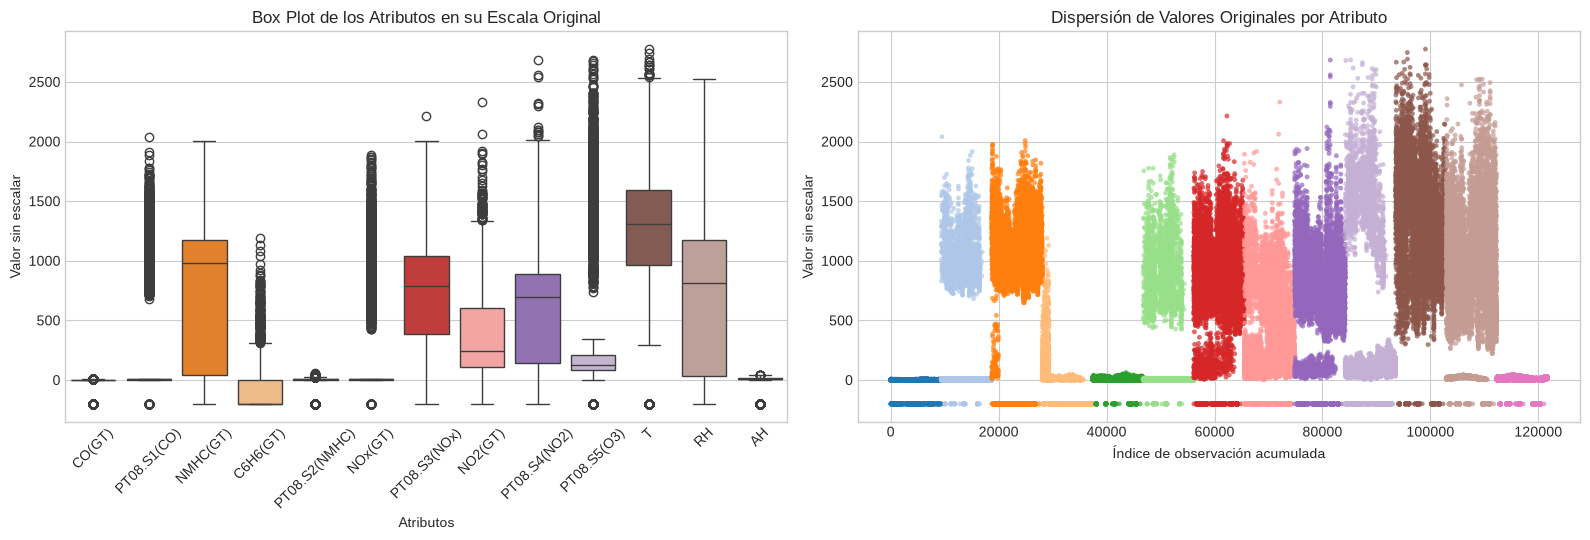

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Boxplot de las variables en su escala original
sns.boxplot(x='variable', y='value', data=df_cols.melt(), ax=axes[0], palette='tab20')
axes[0].set_title('Box Plot de los Atributos en su Escala Original')
axes[0].set_xlabel('Atributos')
axes[0].set_ylabel('Valor sin escalar')
axes[0].tick_params(axis='x', rotation=45)

# Scatter plot de las variables en su escala original
melted_orig = df_cols.melt()
sns.scatterplot(
    x=melted_orig.index,
    y=melted_orig['value'],
    hue=melted_orig['variable'],
    ax=axes[1],
    palette='tab20',
    s=12,
    linewidth=0,
    alpha=0.7,
    legend=False
)
axes[1].set_title('Dispersión de Valores Originales por Atributo')
axes[1].set_xlabel('Índice de observación acumulada')
axes[1].set_ylabel('Valor sin escalar')

plt.tight_layout()
plt.show()

## 4. Evaluación de los Métodos de Escalado y Aplicación

A partir de los métodos vistos en teoría (Scaling.ipynb), se analizan las alternativas frente al requisito de dejar todos los valores numéricos dentro del rango de 0 a 1 para un modelo de regresión:

1. Escalador estándar (StandardScaler): Centra la media en 0 y la desviación estándar en 1, generando valores negativos y positivos fuera del intervalo [0, 1]. No cumple con la restricción de rango.
2. Escalador de máximo absoluto (MaxAbsScaler): Divide por el valor máximo absoluto dejando los datos entre -1 y 1. Como el dataset tiene valores negativos (-200), el límite inferior queda en -1 y no en 0. No cumple con la restricción de rango.
3. Escalador robusto (RobustScaler): Utiliza el rango intercuartílico (Q1 y Q3), por lo que no acota los valores entre 0 y 1. No cumple con la restricción de rango.
4. Escalador máximo-mínimo (MinMaxScaler): Transforma linealmente los datos exactamente al rango [0, 1] mediante la fórmula (x - min) / (max - min). Conserva intacta la relación proporcional entre los datos de cada atributo, aunque si se aplica directamente sobre los valores crudos con atípicos (-200), las observaciones normales quedan comprimidas. Si se reemplazan previamente los códigos -200, el escalado aprovecha todo el recorrido de 0 a 1 sin perder linealidad.
5. Escalador de transformación de cuartil (QuantileTransformer): También lleva todos los datos al rango [0, 1], mapeando la distribución a través de cuantiles. Tiene la ventaja de ser muy eficiente frente a valores atípicos sin necesidad de recortarlos, aunque al ser una transformación no lineal puede modificar levemente la correlación entre variables.

A continuación se aplican y comparan ambos métodos que garantizan el rango de 0 a 1 (MinMaxScaler y QuantileTransformer), incluyendo además el efecto de tratar el valor centinela -200 antes de aplicar MinMaxScaler.

### 4.1 Aplicación del Escalador Máximo-Mínimo (MinMaxScaler)

In [5]:
# Crear y ajustar MinMaxScaler sobre las columnas numéricas
scaler_minmax = MinMaxScaler()
df_cols_maxmin = pd.DataFrame(scaler_minmax.fit_transform(df_cols), columns=df_cols.columns)

print("Verificación de rango con MinMaxScaler:")
display(df_cols_maxmin.describe().T[['min', '25%', '50%', 'mean', '75%', 'max', 'std']])

Verificación de rango con MinMaxScaler:


,min,25%,50%,mean,75%,max,std
CO(GT),0.0,0.947867,0.952607,0.783990,0.957346,1.0,0.367223
PT08.S1(CO),0.0,0.090625,0.091964,0.196771,0.093304,1.0,0.203547
NMHC(GT),0.0,0.108243,0.534873,0.439851,0.620924,1.0,0.271050
C6H6(GT),0.0,0.000000,0.000000,0.059374,0.146868,1.0,0.106314
PT08.S2(NMHC),0.0,0.771863,0.783270,0.766544,0.802281,1.0,0.143154
NOx(GT),0.0,0.096697,0.098612,0.196347,0.100048,1.0,0.195564
PT08.S3(NOx),0.0,0.241508,0.410522,0.363864,0.513670,1.0,0.210354
NO2(GT),0.0,0.122481,0.176610,0.223598,0.316081,1.0,0.138907
PT08.S4(NO2),0.0,0.119667,0.310441,0.273884,0.378425,1.0,0.162723
PT08.S5(O3),0.0,0.098474,0.112344,0.213909,0.142857,1.0,0.216161


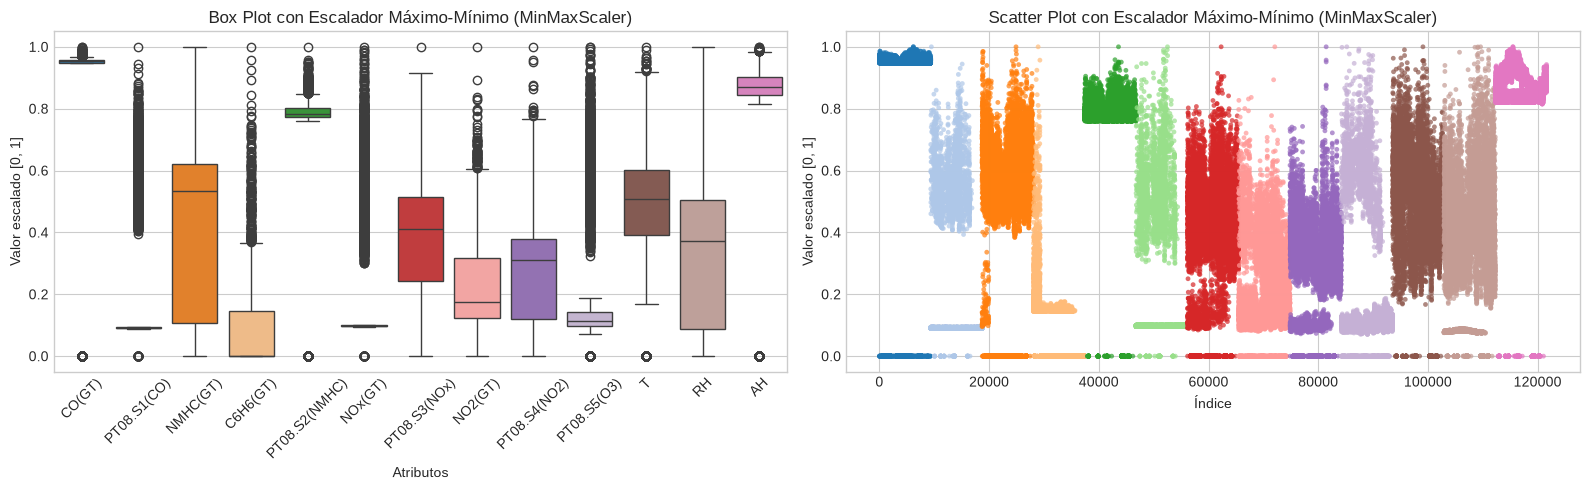

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='variable', y='value', data=df_cols_maxmin.melt(), ax=axes[0], palette='tab20')
axes[0].set_title('Box Plot con Escalador Máximo-Mínimo (MinMaxScaler)')
axes[0].set_xlabel('Atributos')
axes[0].set_ylabel('Valor escalado [0, 1]')
axes[0].tick_params(axis='x', rotation=45)

melted_mm = df_cols_maxmin.melt()
sns.scatterplot(
    x=melted_mm.index,
    y=melted_mm['value'],
    hue=melted_mm['variable'],
    ax=axes[1],
    palette='tab20',
    s=12,
    linewidth=0,
    alpha=0.7,
    legend=False
)
axes[1].set_title('Scatter Plot con Escalador Máximo-Mínimo (MinMaxScaler)')
axes[1].set_xlabel('Índice')
axes[1].set_ylabel('Valor escalado [0, 1]')

plt.tight_layout()
plt.show()

### 4.2 Aplicación del Escalador de Transformación de Cuartil (QuantileTransformer)

In [7]:
# Crear y ajustar QuantileTransformer sobre las columnas numéricas
scaler_tq = QuantileTransformer(random_state=42)
df_cols_tq = pd.DataFrame(scaler_tq.fit_transform(df_cols), columns=df_cols.columns)

print("Verificación de rango con QuantileTransformer:")
display(df_cols_tq.describe().T[['min', '25%', '50%', 'mean', '75%', 'max', 'std']])

Verificación de rango con QuantileTransformer:


,min,25%,50%,mean,75%,max,std
CO(GT),0.0,0.262763,0.483483,0.483845,0.712713,1.0,0.307648
PT08.S1(CO),0.0,0.233233,0.493994,0.500077,0.739239,1.0,0.287951
NMHC(GT),0.0,0.250159,0.500000,0.469227,0.749750,1.0,0.328793
C6H6(GT),0.0,0.000000,0.000000,0.259692,0.746747,1.0,0.393510
PT08.S2(NMHC),0.0,0.253754,0.468969,0.499522,0.742743,1.0,0.289206
NOx(GT),0.0,0.224725,0.521021,0.499957,0.742242,1.0,0.288091
PT08.S3(NOx),0.0,0.250112,0.500501,0.486302,0.750751,1.0,0.308798
NO2(GT),0.0,0.249750,0.499499,0.498806,0.749750,1.0,0.290708
PT08.S4(NO2),0.0,0.249750,0.499499,0.486257,0.749249,1.0,0.308851
PT08.S5(O3),0.0,0.250250,0.498999,0.498783,0.749750,1.0,0.290728


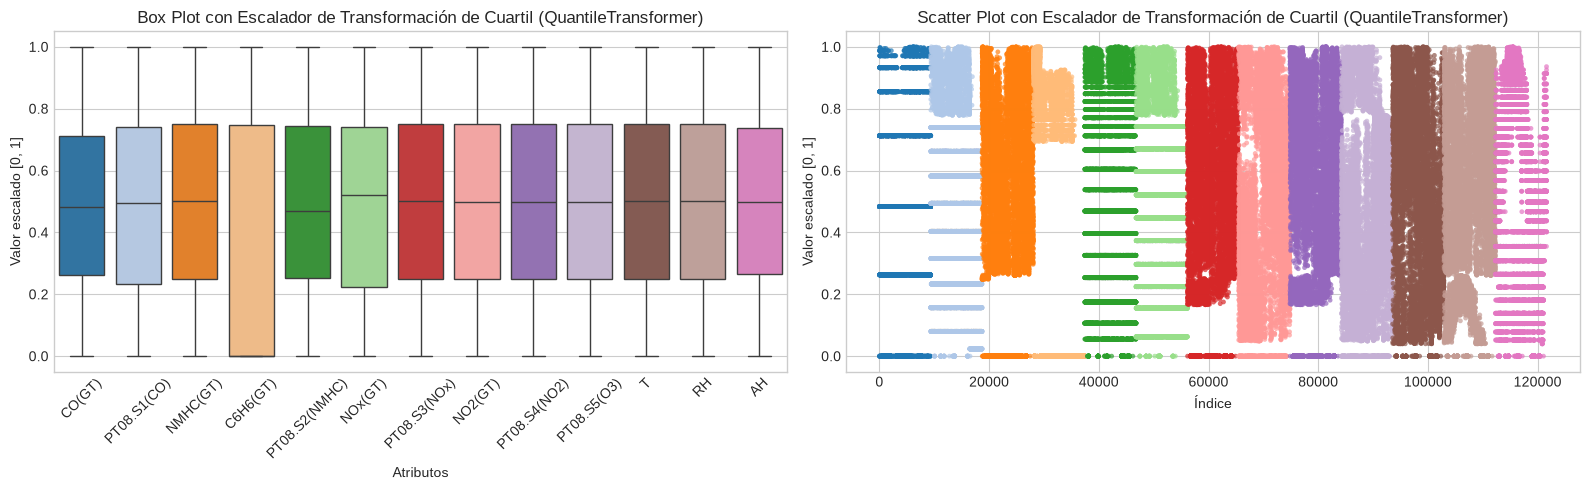

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='variable', y='value', data=df_cols_tq.melt(), ax=axes[0], palette='tab20')
axes[0].set_title('Box Plot con Escalador de Transformación de Cuartil (QuantileTransformer)')
axes[0].set_xlabel('Atributos')
axes[0].set_ylabel('Valor escalado [0, 1]')
axes[0].tick_params(axis='x', rotation=45)

melted_tq = df_cols_tq.melt()
sns.scatterplot(
    x=melted_tq.index,
    y=melted_tq['value'],
    hue=melted_tq['variable'],
    ax=axes[1],
    palette='tab20',
    s=12,
    linewidth=0,
    alpha=0.7,
    legend=False
)
axes[1].set_title('Scatter Plot con Escalador de Transformación de Cuartil (QuantileTransformer)')
axes[1].set_xlabel('Índice')
axes[1].set_ylabel('Valor escalado [0, 1]')

plt.tight_layout()
plt.show()

### 4.3 Alternativa Complementaria: Limpieza de Centinelas (-200) + MinMaxScaler

Dado que en un análisis de regresión es deseable conservar las relaciones lineales entre las variables sin que el valor artificial -200 distorsione el mínimo, se muestra también cómo se comporta MinMaxScaler cuando los valores -200 se tratan previamente como faltantes y se imputan por la mediana de cada sensor.

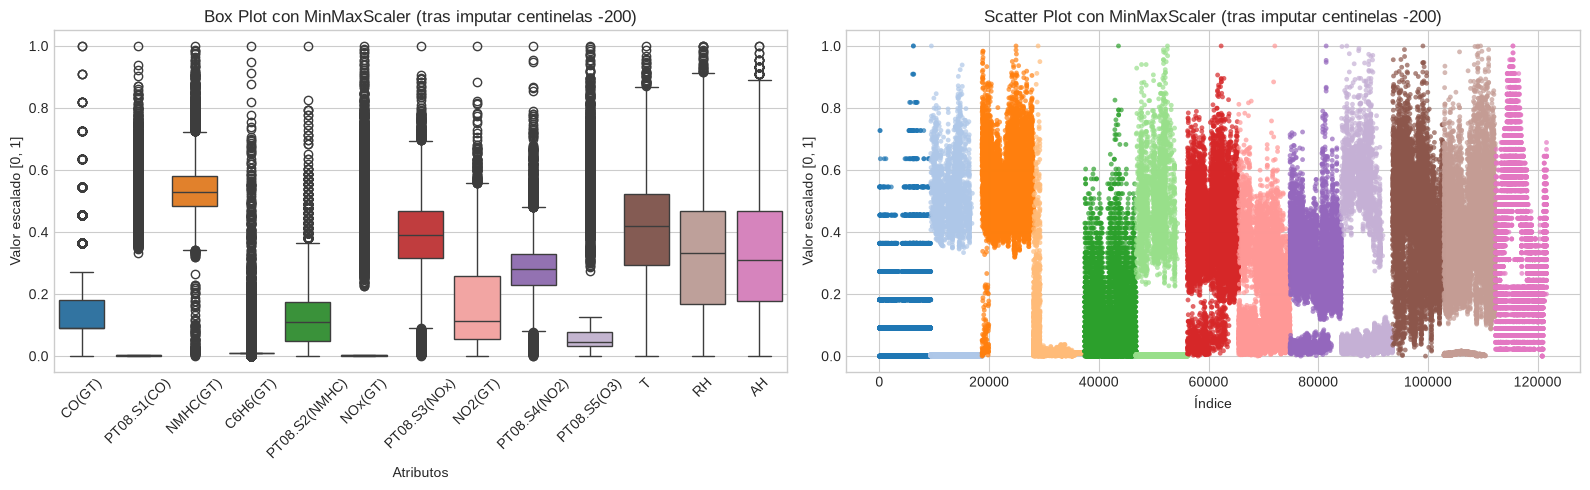

In [9]:
# Reemplazo del código centinela -200 por NaN e imputación por mediana antes de MinMaxScaler
df_cols_sin_200 = df_cols.replace(-200, np.nan)
df_cols_sin_200 = df_cols_sin_200.fillna(df_cols_sin_200.median())

scaler_minmax_clean = MinMaxScaler()
df_cols_maxmin_clean = pd.DataFrame(scaler_minmax_clean.fit_transform(df_cols_sin_200), columns=df_cols.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='variable', y='value', data=df_cols_maxmin_clean.melt(), ax=axes[0], palette='tab20')
axes[0].set_title('Box Plot con MinMaxScaler (tras imputar centinelas -200)')
axes[0].set_xlabel('Atributos')
axes[0].set_ylabel('Valor escalado [0, 1]')
axes[0].tick_params(axis='x', rotation=45)

melted_mmc = df_cols_maxmin_clean.melt()
sns.scatterplot(
    x=melted_mmc.index,
    y=melted_mmc['value'],
    hue=melted_mmc['variable'],
    ax=axes[1],
    palette='tab20',
    s=12,
    linewidth=0,
    alpha=0.7,
    legend=False
)
axes[1].set_title('Scatter Plot con MinMaxScaler (tras imputar centinelas -200)')
axes[1].set_xlabel('Índice')
axes[1].set_ylabel('Valor escalado [0, 1]')

plt.tight_layout()
plt.show()

## 5. Justificación de la Elección

1. Cumplimiento estricto del rango [0, 1]:
   Entre los cinco métodos estudiados en la práctica, únicamente MinMaxScaler y QuantileTransformer garantizan que todos los atributos queden acotados exactamente entre 0 y 1. StandardScaler y RobustScaler producen valores abiertos por encima de 1 y por debajo de 0, mientras que MaxAbsScaler genera valores en [-1, 1] debido a la presencia de números negativos en el dataset.

2. Necesidad de escalar por diferencia de magnitudes:
   En el dataset original las variables tienen rangos muy dispares: mientras AH se mueve entre 0 y 44 y CO(GT) llega hasta 11, los sensores de óxidos y benceno (PT08.S1 a PT08.S5) alcanzan valores superiores a 2000. Sin escalado, el algoritmo de regresión le otorgaría un peso desproporcionado a las variables con números más grandes por el simple hecho de su escala de medición.

3. Elección entre QuantileTransformer y MinMaxScaler:
   - Si se trabaja directamente sobre el dataset crudo sin modificar los valores atípicos (donde abundan lecturas en -200 y picos altos de concentración), el método más adecuado es QuantileTransformer. Como se ve en los gráficos de caja, MinMaxScaler sobre datos crudos queda tironeado por el extremo -200 y comprime las mediciones reales en una franja pequeña, mientras que QuantileTransformer utiliza la distribución acumulada por cuantiles, neutraliza el impacto de los valores atípicos y reparte de forma pareja todas las variables dentro del intervalo de 0 a 1 (con mediana en 0.5).
   - Por otro lado, si en el preprocesamiento previo se corrigen primero los valores centinela -200 (imputándolos con la mediana), MinMaxScaler resulta ideal para la regresión porque mantiene la proporción lineal exacta entre los puntos de cada atributo sin alterar las correlaciones originales entre variables.